**Project:** Estimating On-Demand Delivery Durations and Operational Delay Risks  
**Dataset:** DoorDash historical delivery data (Kaggle)

# Data Preprocessing

## 1. Load and Inspect

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 50)

RAW_PATH = Path("data/raw/historical_data.csv")
OUT_DIR  = Path("data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR  = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

TEST_SIZE      = 0.20   # latest 20% of orders = test set
DELAY_PCTL     = 0.75   # delayed = duration above the 75th percentile (Proposal 6.1)
MIN_DURATION   = 5      # minutes – anything faster is treated as a data error
MAX_DURATION   = 180    # minutes – anything slower is treated as a data error (review in EDA)

In [3]:
df_raw = pd.read_csv(RAW_PATH)
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (197428, 16)


,market_id,created_at,actual_delivery_time,store_id,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_order_place_duration,estimated_store_to_consumer_driving_duration
0,1.0,2015-02-06 22:24:17,2015-02-06 23:27:16,1845,american,1.0,4,3441,4,557,1239,33.0,14.0,21.0,446,861.0
1,2.0,2015-02-10 21:49:25,2015-02-10 22:56:29,5477,mexican,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,446,690.0
2,3.0,2015-01-22 20:39:28,2015-01-22 21:09:09,5477,NaN,1.0,1,1900,1,1900,1900,1.0,0.0,0.0,446,690.0
3,3.0,2015-02-03 21:21:45,2015-02-03 22:13:00,5477,NaN,1.0,6,6900,5,600,1800,1.0,1.0,2.0,446,289.0
4,3.0,2015-02-15 02:40:36,2015-02-15 03:20:26,5477,NaN,1.0,3,3900,3,1100,1600,6.0,6.0,9.0,446,650.0


In [4]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 197428 entries, 0 to 197427
Data columns (total 16 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   market_id                                     196441 non-null  float64
 1   created_at                                    197428 non-null  object 
 2   actual_delivery_time                          197421 non-null  object 
 3   store_id                                      197428 non-null  int64  
 4   store_primary_category                        192668 non-null  object 
 5   order_protocol                                196433 non-null  float64
 6   total_items                                   197428 non-null  int64  
 7   subtotal                                      197428 non-null  int64  
 8   num_distinct_items                            197428 non-null  int64  
 9   min_item_price                                19

In [5]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
market_id,196441.0,2.978706,1.524867,1.0,2.0,3.0,4.0,6.0
store_id,197428.0,3530.510272,2053.496711,1.0,1686.0,3592.0,5299.0,6987.0
order_protocol,196433.0,2.882352,1.503771,1.0,1.0,3.0,4.0,7.0
total_items,197428.0,3.196391,2.666546,1.0,2.0,3.0,4.0,411.0
subtotal,197428.0,2682.331402,1823.093688,0.0,1400.0,2200.0,3395.0,27100.0
num_distinct_items,197428.0,2.670791,1.630255,1.0,1.0,2.0,3.0,20.0
min_item_price,197428.0,686.218470,522.038648,-86.0,299.0,595.0,949.0,14700.0
max_item_price,197428.0,1159.588630,558.411377,0.0,800.0,1095.0,1395.0,14700.0
total_onshift_dashers,181166.0,44.808093,34.526783,-4.0,17.0,37.0,65.0,171.0
total_busy_dashers,181166.0,41.739747,32.145733,-5.0,15.0,34.0,62.0,154.0


## 2. Data Quality Report

In [6]:
quality = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "missing_%": (df_raw.isna().mean() * 100).round(2),
    "n_unique": df_raw.nunique(),
})
num = df_raw.select_dtypes("number")
quality["n_negative"] = (num < 0).sum().reindex(quality.index)
quality

,dtype,missing,missing_%,n_unique,n_negative
market_id,float64,987,0.50,6,0.0
created_at,object,0,0.00,180985,NaN
actual_delivery_time,object,7,0.00,178110,NaN
store_id,int64,0,0.00,6743,0.0
store_primary_category,object,4760,2.41,74,NaN
order_protocol,float64,995,0.50,7,0.0
total_items,int64,0,0.00,57,0.0
subtotal,int64,0,0.00,8368,0.0
num_distinct_items,int64,0,0.00,20,0.0
min_item_price,int64,0,0.00,2312,13.0


In [7]:
print("Duplicate rows:", df_raw.duplicated().sum())
print("Busy riders > on-shift riders:",
      (df_raw["total_busy_dashers"] > df_raw["total_onshift_dashers"]).sum())
print("Min item price > max item price:",
      (df_raw["min_item_price"] > df_raw["max_item_price"]).sum())

Duplicate rows: 0
Busy riders > on-shift riders: 40394
Min item price > max item price: 800


## 3. Target creation - delivery duration (minutes)

In [8]:
df = df_raw.copy()
for col in ["created_at", "actual_delivery_time"]:
    parsed = pd.to_datetime(df[col], format="ISO8601", errors="coerce")
    failed = parsed.isna() & df[col].notna()
    if failed.any():
        print(f"WARNING: {failed.sum()} values in {col} could not be parsed, e.g. {df.loc[failed, col].head(3).tolist()}")
    df[col] = parsed

df["duration_min"] = (df["actual_delivery_time"] - df["created_at"]).dt.total_seconds() / 60
print("Date range:", df["created_at"].min(), "to", df["created_at"].max())
df["duration_min"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])

Date range: 2014-10-19 05:24:15 to 2015-02-18 06:00:44


count    197421.000000
mean         48.470956
std         320.493482
min           1.683333
1%           19.200000
5%           24.866667
25%          35.066667
50%          44.333333
75%          56.350000
95%          81.200000
99%         107.913333
max      141947.650000
Name: duration_min, dtype: float64

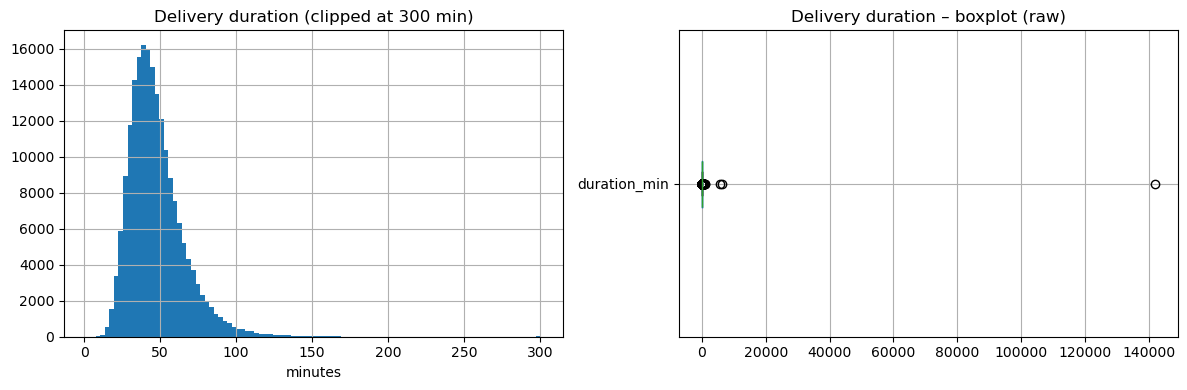

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["duration_min"].clip(upper=300).hist(bins=100, ax=ax[0])
ax[0].set_title("Delivery duration (clipped at 300 min)")
ax[0].set_xlabel("minutes")
df.boxplot(column="duration_min", ax=ax[1], vert=False)
ax[1].set_title("Delivery duration – boxplot (raw)")
plt.tight_layout(); plt.savefig(FIG_DIR / "wk5_duration_raw.png", dpi=150); plt.show()

## 4. Handle invalid values and outliers

In [10]:
log = []
def apply_rule(data, mask_to_drop, reason):
    n = int(mask_to_drop.sum())
    log.append({"step": reason, "rows_removed": n, "rows_remaining": len(data) - n})
    return data.loc[~mask_to_drop].copy()

log.append({"step": "Raw data", "rows_removed": 0, "rows_remaining": len(df)})

df = apply_rule(df, df.duplicated(), "Duplicate rows")
df = apply_rule(df, df["duration_min"].isna(), "Missing delivery or order timestamp (no target)")
df = apply_rule(df, df["duration_min"] < MIN_DURATION, f"Duration < {MIN_DURATION} min")
df = apply_rule(df, df["duration_min"] > MAX_DURATION, f"Duration > {MAX_DURATION} min")

for col in ["total_onshift_dashers", "total_busy_dashers", "total_outstanding_orders"]:
    df = apply_rule(df, df[col] < 0, f"Negative {col}")

df = apply_rule(df, df["min_item_price"] < 0, "Negative min_item_price")
df = apply_rule(df, df["subtotal"] <= 0, "Subtotal <= 0")
df = apply_rule(df, df["total_items"] <= 0, "total_items <= 0")

cleaning_log = pd.DataFrame(log)
cleaning_log["%_of_raw"] = (cleaning_log["rows_remaining"] / len(df_raw) * 100).round(2)
cleaning_log

,step,rows_removed,rows_remaining,%_of_raw
0,Raw data,0,197428,100.00
1,Duplicate rows,0,197428,100.00
2,Missing delivery or order timestamp (no target),7,197421,100.00
3,Duration < 5 min,3,197418,99.99
4,Duration > 180 min,138,197280,99.93
5,Negative total_onshift_dashers,21,197259,99.91
6,Negative total_busy_dashers,20,197239,99.90
7,Negative total_outstanding_orders,40,197199,99.88
8,Negative min_item_price,13,197186,99.88
9,Subtotal <= 0,179,197007,99.79


In [11]:
over = df["total_busy_dashers"] > df["total_onshift_dashers"]
print("Rows capped:", int(over.sum()))
df.loc[over, "total_busy_dashers"] = df.loc[over, "total_onshift_dashers"]

Rows capped: 40289


## 5. Unit conversion

In [12]:
for col in ["subtotal", "min_item_price", "max_item_price"]:
    df[col] = df[col] / 100 # cents to dollars

for col in ["estimated_order_place_duration", "estimated_store_to_consumer_driving_duration"]:
    df[col] = df[col] / 60  # seconds to minutes

df[["subtotal", "min_item_price", "max_item_price",
    "estimated_order_place_duration", "estimated_store_to_consumer_driving_duration"]].describe().T

,count,mean,std,min,25%,50%,75%,max
subtotal,197007.0,26.848073,18.222115,0.95,14.010000,22.000000,33.960000,271.00
min_item_price,197007.0,6.861217,5.217357,0.00,2.990000,5.950000,9.490000,147.00
max_item_price,197007.0,11.595669,5.581944,0.00,8.000000,10.950000,13.950000,147.00
estimated_order_place_duration,197007.0,5.142130,1.502131,0.00,4.183333,4.183333,7.433333,45.25
estimated_store_to_consumer_driving_duration,196483.0,9.088356,3.655657,0.00,6.366667,9.066667,11.700000,34.80


## 6. Fill missing categories using the store's other orders
A store always has the same market and category, so a missing value can be recovered from that store's other orders.

In [13]:
for col in ["market_id", "store_primary_category", "order_protocol"]:
    before = df[col].isna().sum()
    store_mode = df.groupby("store_id")[col].agg(lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)
    df[col] = df[col].fillna(df["store_id"].map(store_mode))
    print(f"{col}: {before} missing -> {df[col].isna().sum()} after store-based fill")

market_id: 987 missing -> 3 after store-based fill
store_primary_category: 4753 missing -> 866 after store-based fill
order_protocol: 994 missing -> 3 after store-based fill


## 7. Chronological train/test split
Earliest 80% of orders - training set, latest 20% - test set (Proposal 6.3f).

In [14]:
df = df.sort_values("created_at").reset_index(drop=True)
cutoff_idx = int(len(df) * (1 - TEST_SIZE))
cutoff_time = df.loc[cutoff_idx, "created_at"]

train = df.iloc[:cutoff_idx].copy()
test  = df.iloc[cutoff_idx:].copy()
print(f"Train: {len(train):,} orders  ({train.created_at.min()} to {train.created_at.max()})")
print(f"Test : {len(test):,} orders  ({test.created_at.min()} to {test.created_at.max()})")

Train: 157,605 orders  (2015-01-21 15:22:03 to 2015-02-13 04:06:56)
Test : 39,402 orders  (2015-02-13 04:07:01 to 2015-02-18 06:00:44)


## 8. Delay label
The threshold is the 75th percentile of the **training set only**, the test set must not influence it.

In [15]:
delay_threshold = train["duration_min"].quantile(DELAY_PCTL)
print(f"Delay threshold: {delay_threshold:.1f} minutes")

for part in (train, test):
    part["is_delayed"] = (part["duration_min"] > delay_threshold).astype(int)

print("Delay rate - train:", round(train.is_delayed.mean(), 3), "| test:", round(test.is_delayed.mean(), 3))

Delay threshold: 55.6 minutes
Delay rate - train: 0.25 | test: 0.301


## 9. Impute remaining missing values
Medians come from the **training set only** and are then applied to both sets.
Categories that are still missing become `"unknown"`.

In [16]:
num_cols = ["total_onshift_dashers", "total_busy_dashers", "total_outstanding_orders",
            "estimated_order_place_duration", "estimated_store_to_consumer_driving_duration"]

# median per market (falls back to the overall median)
market_medians = train.groupby("market_id")[num_cols].median()
overall_medians = train[num_cols].median()

for part in (train, test):
    for col in num_cols:
        fill = part["market_id"].map(market_medians[col]).fillna(overall_medians[col])
        part[col] = part[col].fillna(fill)
    for col in ["market_id", "store_primary_category", "order_protocol"]:
        part[col] = part[col].fillna("unknown")

print("Missing values left – train:", int(train.isna().sum().sum()), "| test:", int(test.isna().sum().sum()))

Missing values left – train: 0 | test: 0


In [17]:
train.to_csv(OUT_DIR / "train_clean.csv", index=False)
test.to_csv(OUT_DIR / "test_clean.csv", index=False)
cleaning_log.to_csv(OUT_DIR / "cleaning_log.csv", index=False)

summary = {
    "raw_rows": len(df_raw),
    "clean_rows": len(train) + len(test),
    "train_rows": len(train),
    "test_rows": len(test),
    "split_cutoff": str(cutoff_time),
    "delay_threshold_min": round(delay_threshold, 2),
    "delay_rate_train": round(train.is_delayed.mean(), 4),
}
pd.Series(summary)

raw_rows                            197428
clean_rows                          197007
train_rows                          157605
test_rows                            39402
split_cutoff           2015-02-13 04:07:01
delay_threshold_min                  55.65
delay_rate_train                    0.2499
dtype: object

# Feature Engineering and Exploratory Data Analysis


**Part 1 - Feature engineering:**
- 1.1 time features
- 1.2 operational pressure
- 1.3 order features
- 1.4 store history
- 1.5 rare categories


**Part 2 - EDA (training set only):**
- 2.1 duration
- 2.2 train vs. test
- 2.3 time
- 2.4 market & category
- 2.5 operational pressure
- 2.6 store history
- 2.7 correlation
- 2.8 delayed vs. on-time

**Part 3 - Encoding and saving model-ready data**

In [18]:
import matplotlib.ticker as mtick

LOCAL_UTC_OFFSET = -8      # hours; US Pacific time in Jan–Feb (no daylight saving).
MIN_CATEGORY_ORDERS = 500  # store categories with fewer training orders become "other"
SMOOTHING = 20             # store history: weight of the category average

# Chart style (consistent across all report figures)
BLUE, ORANGE = "#2a78d6", "#eb6834"      # main series / highlight (delayed, threshold, test)
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": INK_2, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})
def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

In [19]:
for part in (train, test):
    # market_id and order_protocol now contain "unknown", so treat them as categories (e.g. 1.0 > "1")
    for col in ["market_id", "order_protocol"]:
        part[col] = part[col].astype(str).str.replace(".0", "", regex=False)

train = train.sort_values("created_at").reset_index(drop=True)
test  = test.sort_values("created_at").reset_index(drop=True)
DELAY_THRESHOLD = delay_threshold
print(f"Train {train.shape} | Test {test.shape} | delay threshold = {DELAY_THRESHOLD:.1f} min")

Train (157605, 18) | Test (39402, 18) | delay threshold = 55.6 min


## Part 1 - Feature engineering

### 1.1 Time zone check and time features
`created_at` is stored in **UTC**. If the order volume peaks at unusual hours (e.g. 1–4 am), the timestamps need converting to local time before building hour-of-day features.

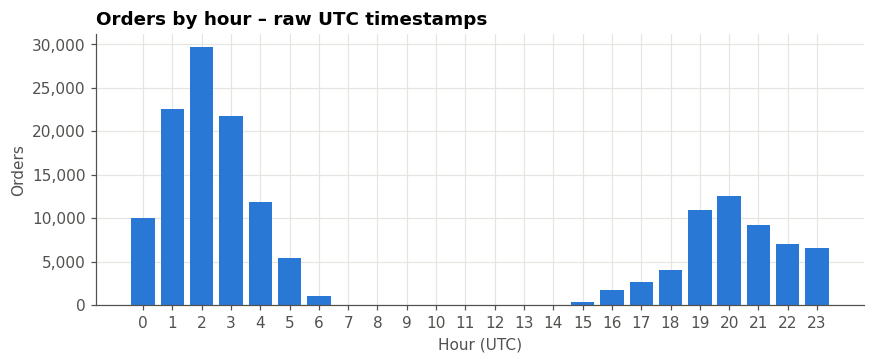

In [30]:
utc_hour = train["created_at"].dt.hour.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(utc_hour.index, utc_hour.values, color=BLUE, width=0.8)
ax.set_title("Orders by hour – raw UTC timestamps")
ax.set_xlabel("Hour (UTC)"); ax.set_ylabel("Orders"); ax.set_xticks(range(0, 24))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
save(fig, "fig_1.1_orders_by_utc_hour")

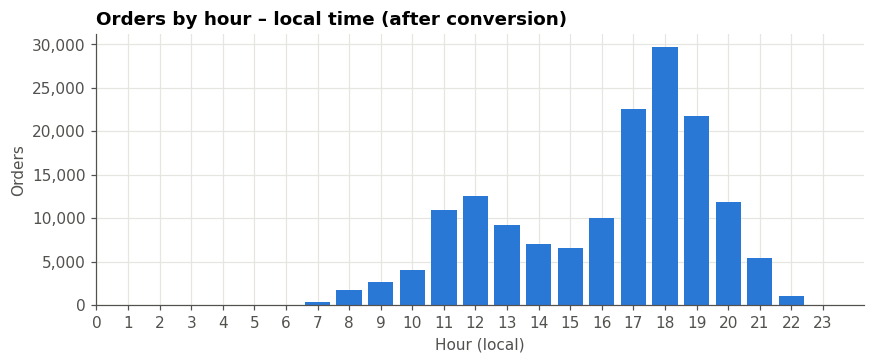

In [31]:
def add_time_features(d):
    local = d["created_at"] + pd.Timedelta(hours=LOCAL_UTC_OFFSET)
    d["hour"] = local.dt.hour
    d["day_of_week"] = local.dt.dayofweek            # 0 = Monday
    d["is_weekend"] = (d["day_of_week"] >= 5).astype(int)
    d["meal_period"] = np.select(
        [d["hour"].between(11, 13), d["hour"].between(17, 20)],
        ["lunch", "dinner"], default="off_peak")
    d["is_peak"] = (d["meal_period"] != "off_peak").astype(int)
    return d

train, test = add_time_features(train), add_time_features(test)

local_hour = train["hour"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(local_hour.index, local_hour.values, color=BLUE, width=0.8)
ax.set_title("Orders by hour – local time (after conversion)")
ax.set_xlabel("Hour (local)"); ax.set_ylabel("Orders"); ax.set_xticks(range(0, 24))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
save(fig, "fig_1.1_orders_by_local_hour")

**Finding:** In raw UTC time, order volume peaks at 01:00-03:00 and 19:00-20:00, which does not match normal meal times. After converting to US Pacific time (UTC-8), the peaks fall at **11:00-12:00 (lunch)** and **17:00-19:00 (dinner)**, with very few orders before 08:00. This confirms that the timestamps are in UTC and that the -8 hour conversion is correct. The busiest hour is **18:00**, with about 30,000 training orders and dinner volume is roughly double lunch volume.

### 1.2 Operational pressure features
These capture how stretched the rider fleet is when the order is placed - the core of the operational delay risk.

| Feature | Formula | Meaning |
|---|---|---|
| `available_dashers` | on-shift - busy | Riders free to take a new order |
| `busy_ratio` | busy ÷ on-shift | Share of the fleet already occupied (0-1) |
| `orders_per_dasher` | outstanding orders / on-shift | Demand pressure per rider |

When no riders are on shift, `busy_ratio` is set to 1 (no free capacity) and `orders_per_dasher` divides by 1 to avoid dividing by zero.

In [22]:
def add_pressure_features(d):
    onshift = d["total_onshift_dashers"]
    d["available_dashers"] = (onshift - d["total_busy_dashers"]).clip(lower=0)
    d["busy_ratio"] = np.where(onshift > 0, d["total_busy_dashers"] / onshift.replace(0, np.nan), 1.0)
    d["orders_per_dasher"] = d["total_outstanding_orders"] / onshift.clip(lower=1)
    return d

train, test = add_pressure_features(train), add_pressure_features(test)
train[["available_dashers", "busy_ratio", "orders_per_dasher"]].describe().T

,count,mean,std,min,25%,50%,75%,max
available_dashers,157605.0,4.656959,8.595342,0.0,0.000000,2.000000,5.000000,86.0
busy_ratio,157605.0,0.890879,0.159256,0.0,0.836735,0.956522,1.000000,1.0
orders_per_dasher,157605.0,1.186384,0.487089,0.0,0.925926,1.185714,1.428571,47.0


**Finding:** The rider fleet is close to full capacity most of the time. The median **busy-rider ratio is 0.96**, and at least a quarter of orders are placed when the ratio is 1.0, meaning every on-shift rider is already busy. The median number of **available riders is only 2**, and at least a quarter of orders are placed with **no free riders at all**. On average there are **1.19 outstanding orders per on-shift rider**, so demand usually exceeds immediate rider supply.

### 1.3 Order features
- `avg_item_price` : subtotal / total items (price level of the order)
- `price_range` : most expensive minus cheapest item. We found ~800 rows where min > max; those are clipped to 0.
- `est_non_prep_time` : estimated order-placement time + estimated driving time: the part of the delivery DoorDash already estimates, leaving food preparation as the unknown.

In [23]:
def add_order_features(d):
    d["avg_item_price"] = d["subtotal"] / d["total_items"]
    d["price_range"] = (d["max_item_price"] - d["min_item_price"]).clip(lower=0)
    d["est_non_prep_time"] = d["estimated_order_place_duration"] + d["estimated_store_to_consumer_driving_duration"]
    return d

train, test = add_order_features(train), add_order_features(test)
train[["avg_item_price", "price_range", "est_non_prep_time"]].describe().T

,count,mean,std,min,25%,50%,75%,max
avg_item_price,157605.0,9.747143,5.150155,0.075791,6.475000,8.95,11.950000,147.00
price_range,157605.0,4.720123,5.143037,0.000000,0.000000,3.60,7.500000,76.74
est_non_prep_time,157605.0,14.208463,3.900377,2.550000,11.366667,14.15,16.916667,53.70


**Finding:** The average item price is about **\$9.75** (median \$8.95), and the median price range within an order is \$3.60. The combined estimate of order-placement and driving time averages **14.2 minutes**, about 30% of the median delivery duration (43.9 minutes, Section 2.1). The rest of the delivery time comes from food preparation and waiting for a rider, which this dataset does not record directly.

### 1.4 Store history features (no data leakage)
A store's past performance is one of the strongest signals of how long its next order will take. It has to be built carefully, because it uses the target.

- **Training set:** each order only sees the store's **earlier** orders (an expanding average). An order never sees its own delivery time or any later one - exactly what would be known in real time.
- **Test set:** uses the store's full training history, frozen at the split date. No test outcomes are used.
- **Smoothing:** a store with only a few past orders gets an estimate pulled towards its **category's average** (weight = `SMOOTHING` orders). A brand-new store gets the category average - this is the cold-start fallback from the proposal.

| Feature | Meaning |
|---|---|
| `store_hist_orders` | Number of earlier orders from this store |
| `store_hist_avg_duration` | Smoothed average delivery time of earlier orders |
| `store_hist_delay_rate` | Smoothed share of earlier orders that were delayed |

In [26]:
# Category-level priors from the training set (fallback: overall average)
cat_dur   = train.groupby("store_primary_category")["duration_min"].mean()
cat_delay = train.groupby("store_primary_category")["is_delayed"].mean()
glob_dur, glob_delay = train["duration_min"].mean(), train["is_delayed"].mean()

def priors(d):
    p_dur = d["store_primary_category"].map(cat_dur).fillna(glob_dur)
    p_del = d["store_primary_category"].map(cat_delay).fillna(glob_delay)
    return p_dur, p_del

# Training set: expanding statistics over each store's EARLIER orders only (train is sorted by time)
g = train.groupby("store_id")
prev_n     = g.cumcount()
prev_dur   = g["duration_min"].cumsum() - train["duration_min"]
prev_delay = g["is_delayed"].cumsum() - train["is_delayed"]
p_dur, p_del = priors(train)
train["store_hist_orders"]       = prev_n
train["store_hist_avg_duration"] = (prev_dur + SMOOTHING * p_dur) / (prev_n + SMOOTHING)
train["store_hist_delay_rate"]   = (prev_delay + SMOOTHING * p_del) / (prev_n + SMOOTHING)

# Test set: full training history per store, frozen at the split
store_stats = train.groupby("store_id").agg(n=("duration_min", "size"),
                                            dur_sum=("duration_min", "sum"),
                                            delay_sum=("is_delayed", "sum"))
n   = test["store_id"].map(store_stats["n"]).fillna(0)
ds  = test["store_id"].map(store_stats["dur_sum"]).fillna(0)
dls = test["store_id"].map(store_stats["delay_sum"]).fillna(0)
p_dur, p_del = priors(test)
test["store_hist_orders"]       = n.astype(int)
test["store_hist_avg_duration"] = (ds + SMOOTHING * p_dur) / (n + SMOOTHING)
test["store_hist_delay_rate"]   = (dls + SMOOTHING * p_del) / (n + SMOOTHING)

new_stores = (n == 0).mean()
print(f"Test orders from stores never seen in training: {new_stores:.1%} (they use the category average)")

Test orders from stores never seen in training: 0.8% (they use the category average)


**Finding:** Only **0.8%** of test orders come from stores that never appear in the training set. For these, the store history features fall back to the category average (the cold-start approach). Because nearly all test orders come from known stores, the store history features can be calculated from real past data for almost the whole test set.

### 1.5 Group rare store categories
Categories with fewer than `MIN_CATEGORY_ORDERS` training orders are merged into `"other"`, so the model is not given dozens of near-empty categories. The list is decided on the **training set** and applied unchanged to the test set.

In [27]:
cat_counts = train["store_primary_category"].value_counts()
keep = cat_counts[cat_counts >= MIN_CATEGORY_ORDERS].index
for part in (train, test):
    part["category_grouped"] = part["store_primary_category"].where(
        part["store_primary_category"].isin(keep), "other")

print(f"{train.store_primary_category.nunique()} categories -> {len(keep)} kept + 'other'")
print(f"Share of training orders in 'other': {(train.category_grouped == 'other').mean():.1%}")

75 categories -> 36 kept + 'other'
Share of training orders in 'other': 5.1%


**Finding:** The 75 original store categories were reduced to **36 categories plus "other"**. The "other" group contains **5.1%** of training orders. This removes many near-empty categories while keeping every category that has enough orders (500 or more) to give a reliable estimate.

## Part 2 Exploratory data analysis
All EDA uses the **training set only**. The test set stays untouched until model evaluation, so nothing here can bias the final results.  
The one exception is 2.2, which compares the two sets' delay rates over time.

### 2.1 Delivery duration distribution

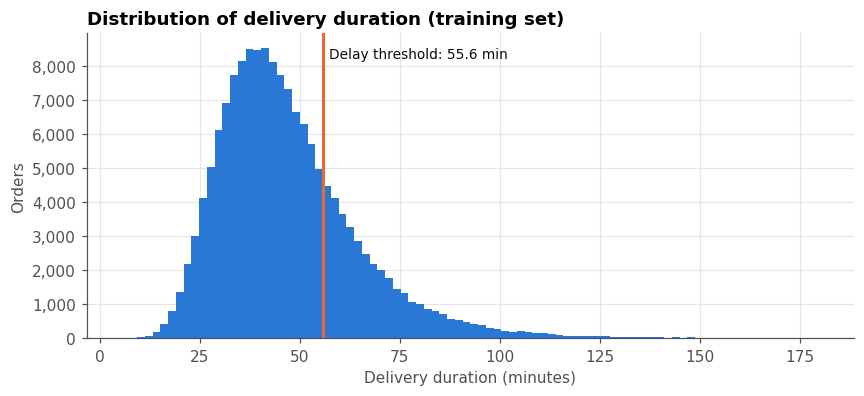

count    157605.0
mean         47.1
std          17.9
min           5.4
25%          34.8
50%          43.9
75%          55.6
90%          69.7
99%         106.1
max         179.8
Name: duration_min, dtype: float64
Skewness: 1.42


In [29]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(train["duration_min"], bins=90, color=BLUE)
ax.axvline(DELAY_THRESHOLD, color=ORANGE, lw=2)
ax.text(DELAY_THRESHOLD + 1.5, ax.get_ylim()[1] * 0.92,
        f"Delay threshold: {DELAY_THRESHOLD:.1f} min", color=INK, fontsize=9)
ax.set_title("Distribution of delivery duration (training set)")
ax.set_xlabel("Delivery duration (minutes)"); ax.set_ylabel("Orders")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
save(fig, "fig_2.1_duration_distribution")

print(train["duration_min"].describe(percentiles=[.25, .5, .75, .9, .99]).round(1))
print("Skewness:", round(train["duration_min"].skew(), 2))

**Finding:** Delivery duration is **right-skewed** (skewness = 1.42). Most orders take **35-56 minutes** (interquartile range), the median is **43.9 minutes** and the mean is **47.1 minutes**. A long tail of slower orders reaches **106 minutes at the 99th percentile**. The mean is higher than the median because of this tail, so the median is the better summary of a typical delivery. The delay threshold of **55.6 minutes** sits at the start of the tail, so "delayed" orders are clearly slower than normal, not just slightly above average.

*Implication for modelling:* because of the skew, RMSE will be noticeably higher than MAE, since a few very slow orders produce large squared errors.

### 2.2 Train vs. test: why the delay rates differ
Previous work showed a **25% delay rate in training but about 30% in the test set**. This chart checks whether delays changed over time.

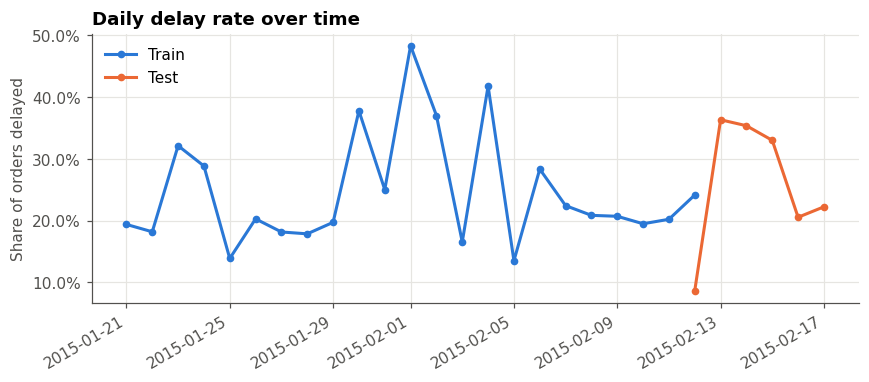

In [36]:
both = pd.concat([train.assign(split="Train"), test.assign(split="Test")])
both["date"] = (both["created_at"] + pd.Timedelta(hours=LOCAL_UTC_OFFSET)).dt.date
daily = both.groupby(["date", "split"]).agg(delay_rate=("is_delayed", "mean"),
                                            orders=("is_delayed", "size")).reset_index()
daily = daily[daily["orders"] >= 200]   # ignore days with very few orders

fig, ax = plt.subplots(figsize=(9, 3.6))
for split, color in [("Train", BLUE), ("Test", ORANGE)]:
    d = daily[daily.split == split]
    ax.plot(pd.to_datetime(d["date"]), d["delay_rate"], color=color, lw=2, marker="o", ms=4, label=split)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Daily delay rate over time")
ax.set_ylabel("Share of orders delayed"); ax.legend(loc="upper left")
fig.autofmt_xdate()
save(fig, "fig_2.2_daily_delay_rate")

**Finding:** The daily delay rate is **highly volatile**, ranging from about **13% to 48%** in the training period. Most days sit around 18-25%, with sharp spikes on a few days. The largest spike (about 48%) is on **1 February 2015**, which coincides with the US Super Bowl, a known peak day for food delivery. The test period (13-17 February) begins with three high-delay days of **33-36%**, around **Valentine's Day weekend (14 February 2015)**, then returns to 20–22%. (The single low point on 12 February is a partial evening, the few hours after the split time.)

This explains why the test delay rate (30%) is higher than the training rate (25%). It is not a data error: the delay threshold was correctly fixed on the training set, and the test period happened to include unusually busy days. This is a form of **distribution shift**. It makes the evaluation more demanding and more realistic, since the models must handle peak conditions not fully represented in training.

### 2.3 Delays by time of day and day of week

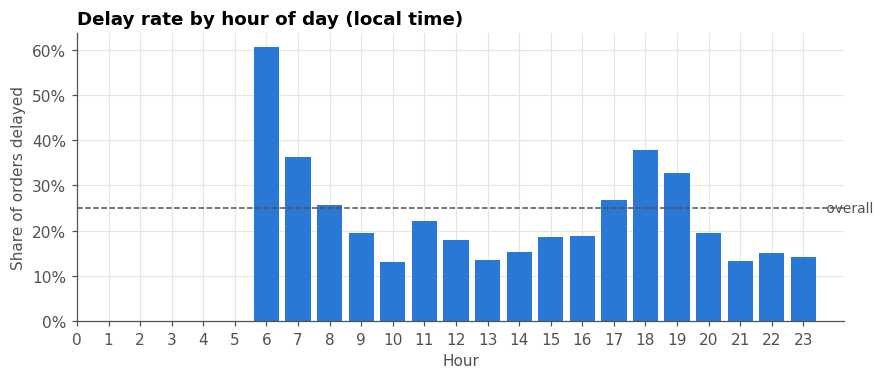

In [37]:
by_hour = train.groupby("hour")["is_delayed"].mean()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(by_hour.index, by_hour.values, color=BLUE, width=0.8)
ax.axhline(train["is_delayed"].mean(), color=INK_2, lw=1, ls="--")
ax.text(23.6, train["is_delayed"].mean(), " overall", va="center", fontsize=9, color=INK_2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xticks(range(0, 24))
ax.set_title("Delay rate by hour of day (local time)")
ax.set_xlabel("Hour"); ax.set_ylabel("Share of orders delayed")
save(fig, "fig_2.3_delay_by_hour")

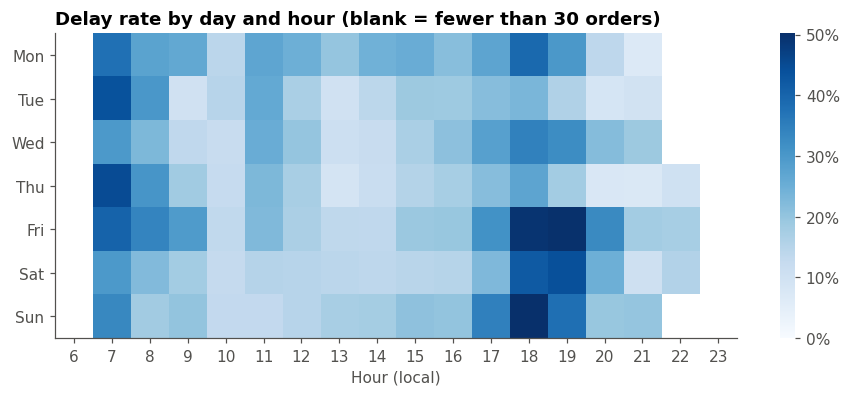

In [34]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
pivot = train.pivot_table(index="day_of_week", columns="hour", values="is_delayed", aggfunc="mean")
counts = train.pivot_table(index="day_of_week", columns="hour", values="is_delayed", aggfunc="size")
pivot = pivot.where(counts >= 30)      # hide cells with too few orders to be reliable

fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(pivot.values, aspect="auto", cmap="Blues", vmin=0)
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels([days[i] for i in pivot.index])
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns)
ax.grid(False)
ax.set_title("Delay rate by day and hour (blank = fewer than 30 orders)")
ax.set_xlabel("Hour (local)")
cb = fig.colorbar(im, ax=ax, format=mtick.PercentFormatter(1.0)); cb.outline.set_visible(False)
save(fig, "fig_b3_delay_heatmap")

**Finding:** Delays follow the **dinner peak**. The delay rate rises from about 19% at 16:00 to **38% at 18:00** and 33% at 19:00, well above the overall rate of 25%. Lunch is less affected: 22% at 11:00 and 18% at 12:00. The lowest delay rates occur mid-afternoon (13:00–14:00) and late evening (21:00–23:00).

The heatmap shows that delays are worst on **Friday, Saturday and Sunday evenings at 18:00–19:00**, where about half of all orders are delayed. Weekday afternoons have the lowest rates.

The very high delay rates at 06:00–07:00 should be **interpreted with caution**: very few orders are placed at these hours (column 06:00 is blank because no day has 30 or more orders), so a small number of slow orders makes the rate look extreme. Early-morning restaurants may also be just opening, which lengthens preparation.

### 2.4 Delays by market and store category

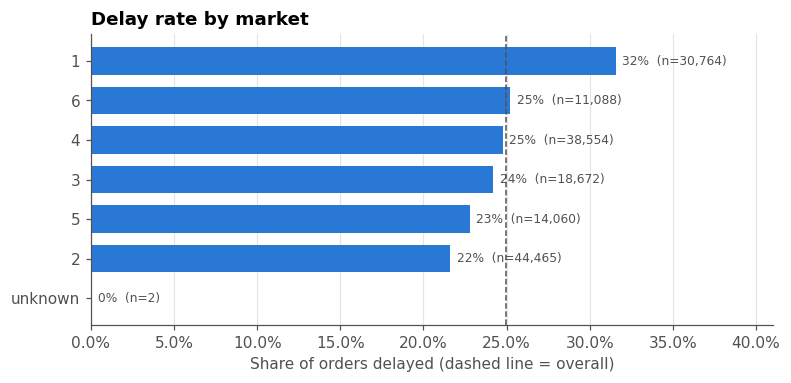

,rate,orders
market_id,,
unknown,0.000000,2
2,0.216215,44465
5,0.227881,14060
3,0.242020,18672
4,0.247601,38554
6,0.252255,11088
1,0.315531,30764


In [38]:
def delay_bar(series, title, fname, min_orders=0):
    stats = train.groupby(series).agg(rate=("is_delayed", "mean"), orders=("is_delayed", "size"))
    stats = stats[stats.orders >= min_orders].sort_values("rate")
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(stats) + 1.2))
    ax.barh(stats.index.astype(str), stats["rate"], color=BLUE, height=0.7)
    ax.axvline(train["is_delayed"].mean(), color=INK_2, lw=1, ls="--")
    for y, (r, n) in enumerate(zip(stats["rate"], stats["orders"])):
        ax.text(r + 0.004, y, f"{r:.0%}  (n={n:,})", va="center", fontsize=8, color=INK_2)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_xlim(0, stats["rate"].max() * 1.3)
    ax.grid(axis="y", visible=False)
    ax.set_title(title); ax.set_xlabel("Share of orders delayed (dashed line = overall)")
    save(fig, fname)
    return stats

delay_bar("market_id", "Delay rate by market", "fig_2.4_delay_by_market")

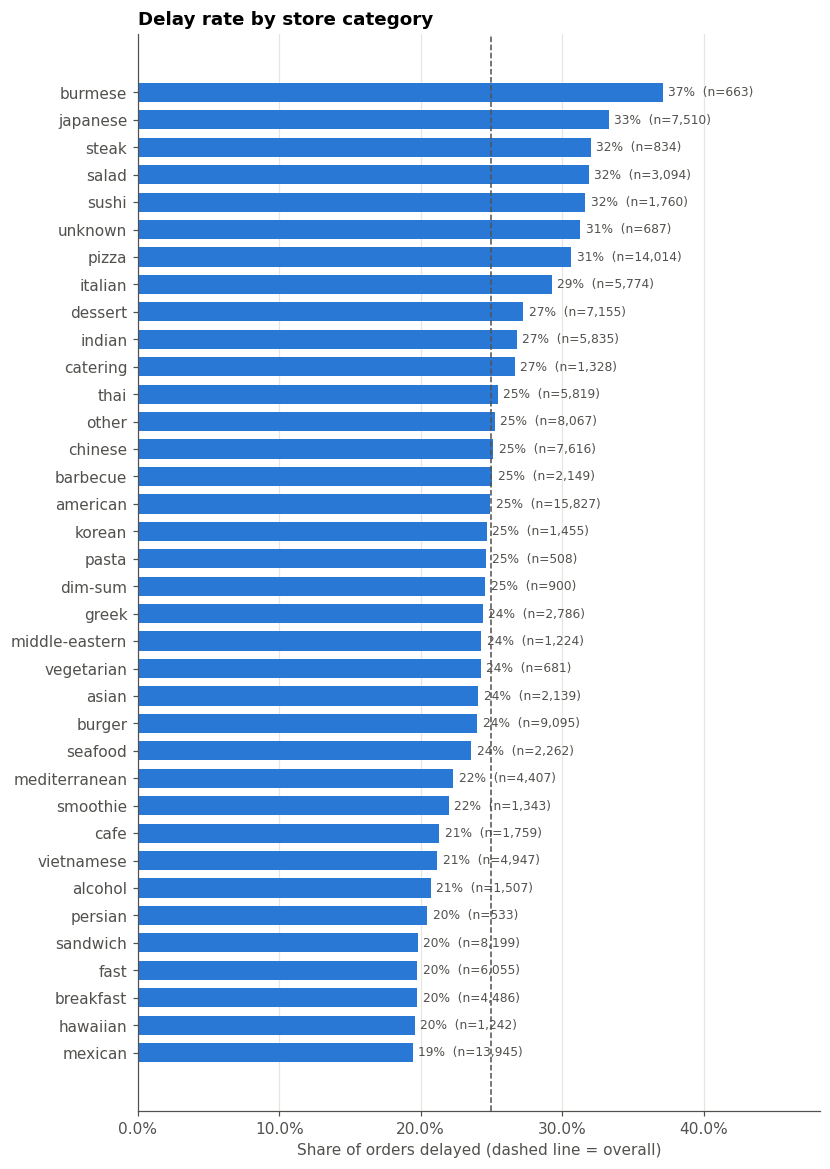

,rate,orders
category_grouped,,
mexican,0.194407,13945
hawaiian,0.195652,1242
breakfast,0.197280,4486
fast,0.197523,6055
sandwich,0.197829,8199
persian,0.204503,533
alcohol,0.207034,1507
vietnamese,0.211846,4947
cafe,0.213189,1759


In [39]:
delay_bar("category_grouped", "Delay rate by store category", "fig_2.4_delay_by_category")

**Finding:** Delay rates differ clearly between **markets**. Market 1 has the highest rate (**31.6%**, 30,764 orders), while market 2 has the lowest (**21.6%**, 44,465 orders), a gap of 10 percentage points. Markets 3–6 sit between 23% and 25%. (The "unknown" market contains only 2 orders and can be ignored.)

**Store category** also matters. Delay rates range from about **19%** for Mexican, breakfast, fast food and sandwich stores to over **30%** for Japanese (33%), sushi (32%), steak (32%), salad (32%) and pizza (31%). Burmese has the highest rate (37%), but with only 663 orders. Categories with fast, standardised preparation tend to have fewer delays, while categories involving made-to-order or more complex dishes (sushi, Japanese, steak, pizza) have more. Pizza is notable because it combines a high delay rate with a large volume (14,014 orders).

Both market and category are therefore useful predictors and are kept as encoded features.

### 2.5 Operational pressure vs. delivery duration
Orders are split into 10 equal-sized groups (deciles) by each pressure feature. If delays rise steadily from left to right, the feature carries useful signal.

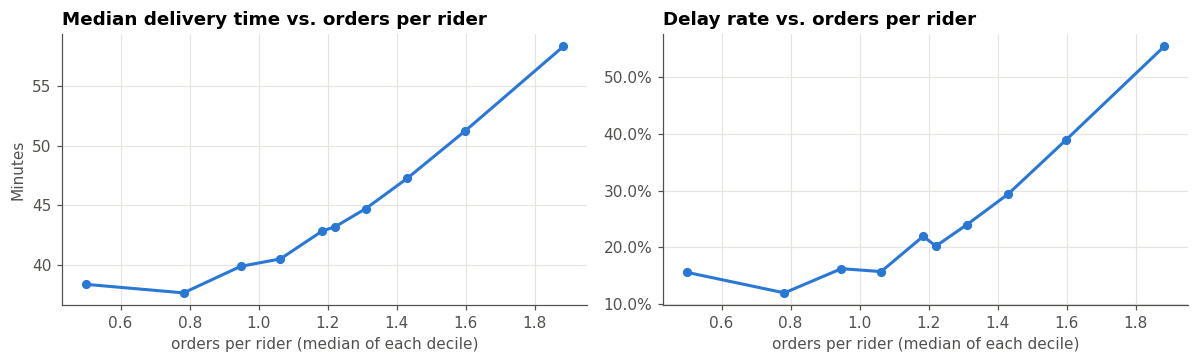

,x,median_duration,delay_rate
bin,,,
"(-0.001, 0.667]",0.500,38.333,0.156
"(0.667, 0.864]",0.782,37.617,0.120
"(0.864, 1.0]",0.947,39.850,0.162
"(1.0, 1.109]",1.062,40.475,0.157
"(1.109, 1.186]",1.184,42.833,0.219
"(1.186, 1.25]",1.221,43.183,0.202
"(1.25, 1.367]",1.310,44.717,0.240
"(1.367, 1.5]",1.430,47.267,0.294
"(1.5, 1.707]",1.598,51.267,0.390


In [41]:
def decile_trend(feature, label, fname):
    d = train[[feature, "duration_min", "is_delayed"]].copy()
    d["bin"] = pd.qcut(d[feature], 10, duplicates="drop")
    s = d.groupby("bin", observed=True).agg(x=(feature, "median"),
                                            median_duration=("duration_min", "median"),
                                            delay_rate=("is_delayed", "mean"))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    axes[0].plot(s["x"], s["median_duration"], color=BLUE, lw=2, marker="o", ms=5)
    axes[0].set_title(f"Median delivery time vs. {label}")
    axes[0].set_ylabel("Minutes")
    axes[1].plot(s["x"], s["delay_rate"], color=BLUE, lw=2, marker="o", ms=5)
    axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    axes[1].set_title(f"Delay rate vs. {label}")
    for ax in axes: ax.set_xlabel(f"{label} (median of each decile)")
    fig.tight_layout()
    save(fig, fname)
    return s.round(3)

decile_trend("orders_per_dasher", "orders per rider", "fig_2.5_orders_per_rider")

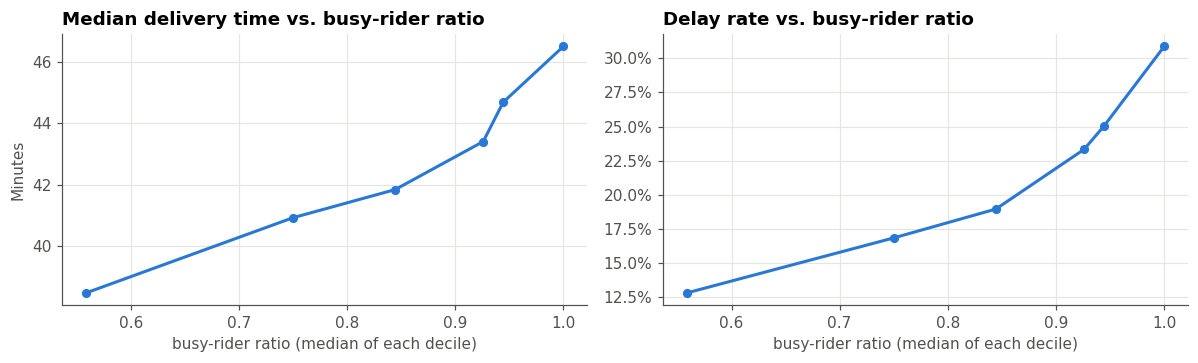

,x,median_duration,delay_rate
bin,,,
"(-0.001, 0.667]",0.559,38.467,0.128
"(0.667, 0.8]",0.750,40.917,0.168
"(0.8, 0.877]",0.844,41.833,0.190
"(0.877, 0.929]",0.926,43.400,0.233
"(0.929, 0.957]",0.944,44.683,0.250
"(0.957, 1.0]",1.000,46.500,0.309


In [42]:
decile_trend("busy_ratio", "busy-rider ratio", "fig_2.5_busy_ratio")

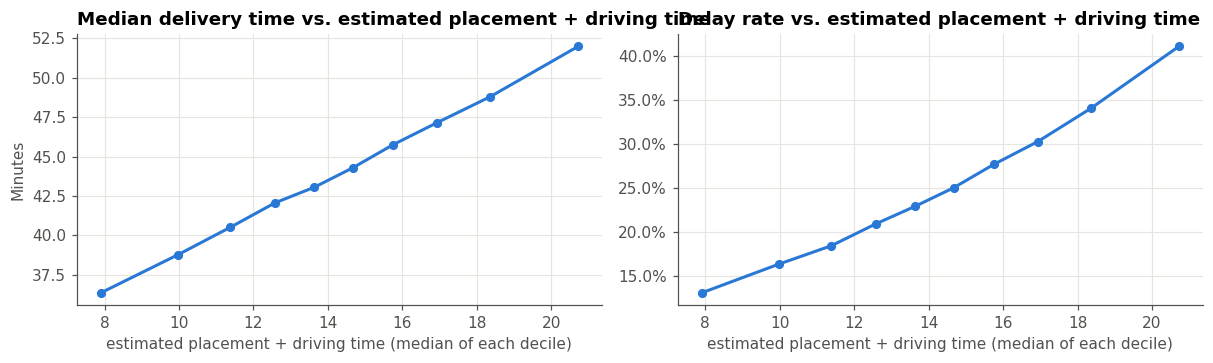

,x,median_duration,delay_rate
bin,,,
"(2.549, 9.1]",7.900,36.350,0.131
"(9.1, 10.717]",9.983,38.783,0.164
"(10.717, 11.983]",11.383,40.517,0.185
"(11.983, 13.117]",12.583,42.067,0.210
"(13.117, 14.15]",13.633,43.050,0.229
"(14.15, 15.2]",14.667,44.283,0.250
"(15.2, 16.317]",15.750,45.750,0.277
"(16.317, 17.567]",16.933,47.150,0.303
"(17.567, 19.333]",18.350,48.783,0.341


In [44]:
decile_trend("est_non_prep_time", "estimated placement + driving time", "fig_2.5_est_time")

**Finding:** This is the strongest evidence for the **operational** side of the project.

- **Orders per rider:** delay risk stays at about **12–16%** while there is up to roughly one outstanding order per rider. Above that point it rises sharply, reaching **55%** in the highest decile, where the median delivery time is **58 minutes**, compared with about 38 minutes when demand is low. The relationship is **non-linear, with a tipping point around 1 order per rider**. Non-linear models such as Random Forest, XGBoost and LightGBM should capture this better than linear models.
- **Busy-rider ratio:** the delay rate rises steadily from **13% to 31%** as the share of busy riders increases. Only 6 groups appear instead of 10 because many orders have the same ratio (exactly 1.0, all riders busy).
- **Estimated placement + driving time:** the delay rate rises evenly from **13% to 41%** across the deciles. Longer estimated travel, which reflects distance, consistently increases delay risk.

Together, these results show that delays depend strongly on how stretched the rider fleet is when the order is placed. This supports Objective 1 and justifies the capacity simulator planned for the dashboard.

### 2.6 Store history vs. delivery duration

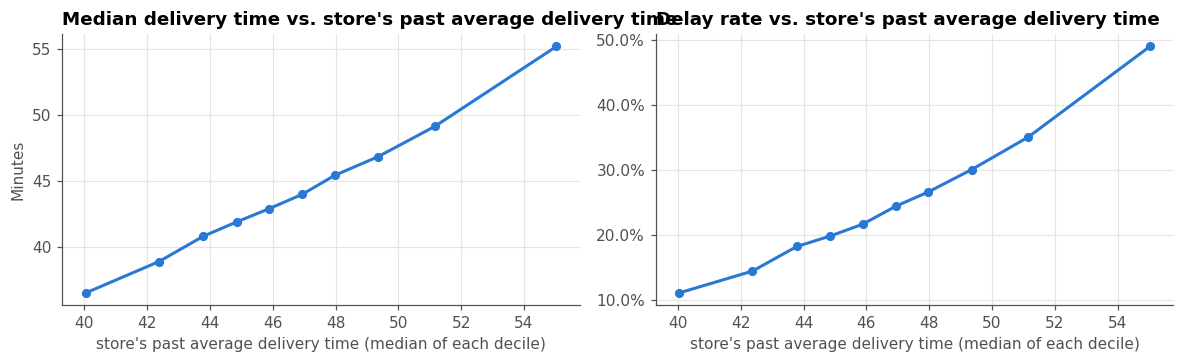

,x,median_duration,delay_rate
bin,,,
"(33.548, 41.433]",40.046,36.533,0.110
"(41.433, 43.125]",42.375,38.900,0.144
"(43.125, 44.312]",43.788,40.817,0.182
"(44.312, 45.358]",44.852,41.900,0.198
"(45.358, 46.402]",45.884,42.900,0.216
"(46.402, 47.4]",46.935,43.983,0.244
"(47.4, 48.597]",47.969,45.417,0.266
"(48.597, 50.104]",49.352,46.833,0.300
"(50.104, 52.577]",51.154,49.117,0.350


In [45]:
decile_trend("store_hist_avg_duration", "store's past average delivery time", "fig_2.6_store_history")

**Finding:** A store's past performance is a strong predictor of its future deliveries. Orders from stores with the fastest history have a **delay rate of 11%** and a median duration of 36.5 minutes. Orders from stores with the slowest history have a **delay rate of 49%** and a median of 55.2 minutes. The increase is steady across all deciles, which confirms that the store history features carry real signal. Because they were built only from each store's earlier orders, this signal does not come from data leakage.

### 2.7 Correlation analysis
**Spearman** correlation is used instead of Pearson because many features are skewed and the relationships are not necessarily linear. Pairs above |0.8| are flagged as **redundant** candidates.

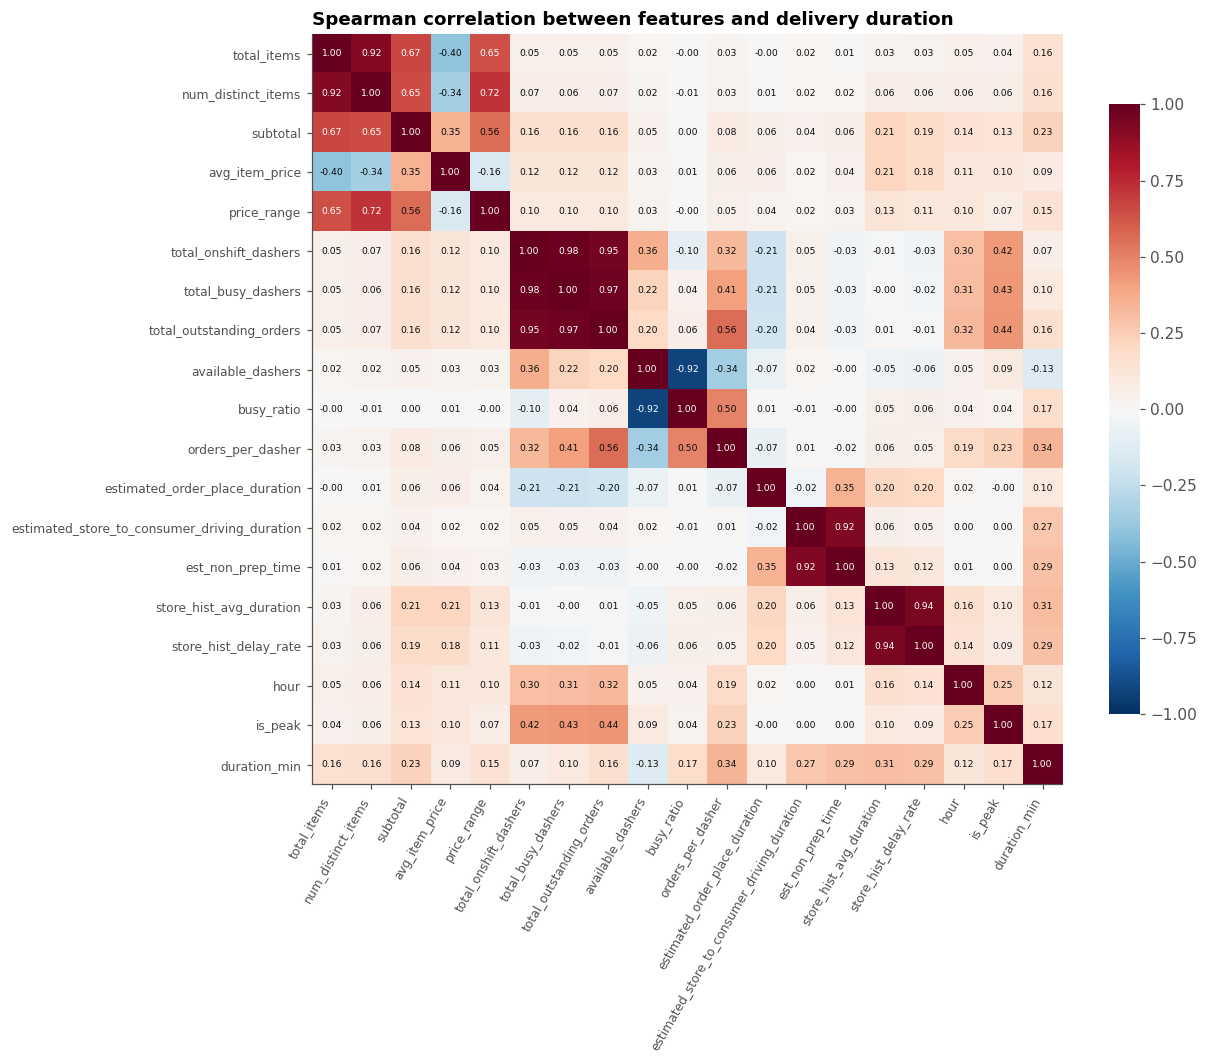

In [46]:
num_features = ["total_items", "num_distinct_items", "subtotal", "avg_item_price", "price_range",
                "total_onshift_dashers", "total_busy_dashers", "total_outstanding_orders",
                "available_dashers", "busy_ratio", "orders_per_dasher",
                "estimated_order_place_duration", "estimated_store_to_consumer_driving_duration",
                "est_non_prep_time", "store_hist_avg_duration", "store_hist_delay_rate",
                "hour", "is_peak", "duration_min"]
corr = train[num_features].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6,
                color="white" if abs(v) > 0.6 else INK)
ax.grid(False)
ax.set_title("Spearman correlation between features and delivery duration")
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.outline.set_visible(False)
save(fig, "fig_2.7_correlation_matrix")

In [47]:
target_corr = corr["duration_min"].drop("duration_min").sort_values(key=abs, ascending=False)
print("Correlation with delivery duration:\n", target_corr.round(3).to_string())

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename("rho").reset_index())
redundant = pairs[(pairs.rho.abs() > 0.8) & (pairs.level_0 != "duration_min") & (pairs.level_1 != "duration_min")]
print("\nHighly correlated feature pairs (|rho| > 0.8):")
redundant.sort_values("rho", key=abs, ascending=False)

Correlation with delivery duration:
 orders_per_dasher                               0.337
store_hist_avg_duration                         0.311
store_hist_delay_rate                           0.293
est_non_prep_time                               0.292
estimated_store_to_consumer_driving_duration    0.272
subtotal                                        0.233
busy_ratio                                      0.175
is_peak                                         0.166
total_outstanding_orders                        0.163
num_distinct_items                              0.161
total_items                                     0.155
price_range                                     0.147
available_dashers                              -0.128
hour                                            0.118
estimated_order_place_duration                  0.100
total_busy_dashers                              0.099
avg_item_price                                  0.085
total_onshift_dashers                        

,level_0,level_1,rho
80,total_onshift_dashers,total_busy_dashers,0.981821
93,total_busy_dashers,total_outstanding_orders,0.973972
81,total_onshift_dashers,total_outstanding_orders,0.954824
161,store_hist_avg_duration,store_hist_delay_rate,0.941574
116,available_dashers,busy_ratio,-0.924850
150,estimated_store_to_consumer_driving_duration,est_non_prep_time,0.922200
0,total_items,num_distinct_items,0.916168


**Finding:** No single feature has a strong correlation with delivery duration. The highest is **orders per rider (ρ = 0.34)**, followed by the **store's past average duration (0.31)**, store past delay rate (0.29), estimated placement + driving time (0.29), driving time (0.27) and order subtotal (0.23). All are moderate at best, which means delivery duration depends on **a combination of factors** rather than one dominant driver. This supports using multivariate machine learning models. Notably, the two strongest predictors are both engineered features, which shows the value of the feature engineering step.

**Redundant feature pairs (|ρ| > 0.9):**
- on-shift riders, busy riders and outstanding orders (ρ = 0.95–0.98): they rise and fall together with overall demand;
- store past average duration and store past delay rate (0.94);
- available riders and busy-rider ratio (−0.92);
- driving time and estimated placement + driving time (0.92);
- total items and distinct items (0.92).

The tree-based models can keep all of these. For **Linear and Logistic Regression**, only one feature from each group will be kept to avoid multicollinearity. The preferred choices are orders per rider, busy-rider ratio, store past average duration, estimated placement + driving time and total items.

### 2.8 Delayed vs. on-time orders

In [48]:
compare_cols = ["orders_per_dasher", "busy_ratio", "available_dashers", "est_non_prep_time",
                "store_hist_avg_duration", "subtotal", "total_items", "is_peak"]
comparison = train.groupby("is_delayed")[compare_cols].median().T
comparison.columns = ["On time (median)", "Delayed (median)"]
comparison["Difference"] = comparison["Delayed (median)"] - comparison["On time (median)"]
comparison.round(2)

,On time (median),Delayed (median),Difference
orders_per_dasher,1.16,1.36,0.20
busy_ratio,0.94,1.00,0.06
available_dashers,2.00,0.00,-2.00
est_non_prep_time,13.70,15.53,1.83
store_hist_avg_duration,45.87,48.08,2.21
subtotal,20.90,26.50,5.60
total_items,2.00,3.00,1.00
is_peak,1.00,1.00,0.00


**Finding:** Compared with on-time orders, a typical **delayed order** is placed when:
- the fleet is busier: **1.36 vs. 1.16 outstanding orders per rider**, and **no available riders** (median 0 vs. 2);
- the expected travel is longer: **+1.8 minutes** of estimated placement + driving time;
- the store is historically slower: **+2.2 minutes** in past average delivery time;
- the order is larger: **3 vs. 2 items**, and **\$26.50 vs. \$20.90** subtotal.

These differences agree with Sections 2.5 and 2.6. The `is_peak` row shows no difference because both groups have a median of 1 (most orders are placed at peak times); the hourly analysis in Section 2.3 is a better guide to the effect of time of day.


## Part 3 - Encoding and saving
- **One-hot encoding** for `market_id`, `order_protocol`, `category_grouped` and `meal_period` (6.3e).
- The test set is given **exactly the same columns** as the training set; any category not seen in training becomes all zeros.
- Identifiers and raw timestamps are dropped, they are not valid model inputs.

In [49]:
cat_cols = ["market_id", "order_protocol", "category_grouped", "meal_period"]
drop_cols = ["created_at", "actual_delivery_time", "store_id", "store_primary_category"]

train_model = pd.get_dummies(train.drop(columns=drop_cols), columns=cat_cols, dtype=int)
test_model  = pd.get_dummies(test.drop(columns=drop_cols),  columns=cat_cols, dtype=int)
test_model  = test_model.reindex(columns=train_model.columns, fill_value=0)

TARGETS = ["duration_min", "is_delayed"]
FEATURES = [c for c in train_model.columns if c not in TARGETS]
print(f"{len(FEATURES)} model features | train {train_model.shape} | test {test_model.shape}")
print("Missing values – train:", int(train_model.isna().sum().sum()), "| test:", int(test_model.isna().sum().sum()))

77 model features | train (157605, 79) | test (39402, 79)
Missing values – train: 0 | test: 0


In [50]:
train.to_csv(OUT_DIR / "train_features.csv", index=False)     # readable version (for EDA / dashboard)
test.to_csv(OUT_DIR / "test_features.csv", index=False)
train_model.to_csv(OUT_DIR / "train_model.csv", index=False)  # encoded version (for modelling)
test_model.to_csv(OUT_DIR / "test_model.csv", index=False)
pd.Series(FEATURES).to_csv(OUT_DIR / "feature_list.csv", index=False, header=["feature"])
print("Saved to", OUT_DIR.resolve())

Saved to C:\Users\User\OneDrive\Desktop\Adam's\Data Science Project\delivery-duration-estimation\data\processed


# Modelling
**Part 4 - Model building:** compare all models on a validation period, using default settings  
**Part 5 - Fine-tuning:** tune XGBoost and LightGBM with time-series cross-validation, then tune the delay threshold  
**Part 6 - Final evaluation on the test set and saving the models**

**Two prediction tasks**
| Task | Target | Type | Main metric |
|---|---|---|---|
| Delivery duration | `duration_min` | Regression | MAE (minutes) |
| Delay risk | `is_delayed` | Classification | Recall, F1, ROC-AUC |

**How the data is used.** The test set (latest 20% of orders) is **not touched until Part 6**. All model comparison and tuning uses the training set only:
- Part 4 splits the training set again by time: earliest 80% → *fit*, latest 20% → *validation*.
- Part 5 uses **time-series cross-validation** on the full training set (each fold trains on earlier orders and validates on later ones).

## Part 4 - Model building


### 4.1 Setup

In [8]:
#pip install xgboost lightgbm joblib
import re, time, json, joblib
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

OUT_DIR = Path("data/processed")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

if "save" not in globals():
    BLUE, ORANGE = "#2a78d6", "#eb6834"
    INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
    plt.rcParams.update({
        "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
        "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "axes.edgecolor": INK_2, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
        "legend.frameon": False,
    })
    def save(fig, name):
        fig.savefig(FIG_DIR / f"{name}.png")
        plt.show()

from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             accuracy_score, roc_curve, confusion_matrix, precision_recall_curve)
from xgboost import XGBRegressor, XGBClassifier
from lightgbm import LGBMRegressor, LGBMClassifier

RANDOM_STATE = 42
FAST_MODE = False      # True = smaller grids
MIN_RECALL = 0.70      # delay classifier must catch at least 70% of delayed orders
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)

if "train_model" not in globals():
    print("Loading model-ready data saved in Part 3 ...")
    train_model = pd.read_csv(OUT_DIR / "train_model.csv")
    test_model  = pd.read_csv(OUT_DIR / "test_model.csv")
if "DELAY_THRESHOLD" not in globals():
    DELAY_THRESHOLD = train_model.loc[train_model.is_delayed == 1, "duration_min"].min()

# XGBoost/LightGBM do not accept some characters in column names (e.g. "-")
clean = lambda c: re.sub(r"[^0-9a-zA-Z_]", "_", c)
TARGETS = ["duration_min", "is_delayed"]
X_all  = train_model.drop(columns=TARGETS).rename(columns=clean)
X_test = test_model.drop(columns=TARGETS).rename(columns=clean)
y_all_reg,  y_test_reg = train_model["duration_min"], test_model["duration_min"]
y_all_clf,  y_test_clf = train_model["is_delayed"],  test_model["is_delayed"]
FEATURES = list(X_all.columns)

# Fit / validation split inside the training set (by time – train_model is in time order)
cut = int(len(X_all) * 0.8)
X_fit, X_val = X_all.iloc[:cut], X_all.iloc[cut:]
y_fit_reg, y_val_reg = y_all_reg.iloc[:cut], y_all_reg.iloc[cut:]
y_fit_clf, y_val_clf = y_all_clf.iloc[:cut], y_all_clf.iloc[cut:]
print(f"Fit: {len(X_fit):,} | Validation: {len(X_val):,} | Test (held out): {len(X_test):,} | Features: {len(FEATURES)}")
print(f"Delay rate – fit {y_fit_clf.mean():.1%} | validation {y_val_clf.mean():.1%} | test {y_test_clf.mean():.1%}")

Fit: 126,084 | Validation: 31,521 | Test (held out): 39,402 | Features: 77
Delay rate – fit 25.9% | validation 21.5% | test 30.1%


### 4.2 Feature set for the linear models
Section 2.7 found groups of highly correlated features (|ρ| > 0.9). Tree models handle these well, but in Linear/Logistic Regression they cause **multicollinearity** (unstable coefficients). For the linear models only:
- keep one feature per redundant group: `orders_per_dasher`, `busy_ratio`, `store_hist_avg_duration`, `est_non_prep_time`, `total_items`;
- drop one dummy column per categorical variable (avoids the "dummy variable trap");
- **standardise** all features (linear models are sensitive to feature scale; tree models are not).

In [9]:
LINEAR_DROP = ["total_onshift_dashers", "total_busy_dashers", "total_outstanding_orders",
               "available_dashers", "store_hist_delay_rate", "num_distinct_items",
               "estimated_store_to_consumer_driving_duration", "is_peak"]
first_dummies = [next(c for c in FEATURES if c.startswith(p))
                 for p in ["market_id_", "order_protocol_", "category_grouped_", "meal_period_"]]
LINEAR_FEATURES = [c for c in FEATURES if c not in LINEAR_DROP + first_dummies]
print(f"Tree models: {len(FEATURES)} features | Linear models: {len(LINEAR_FEATURES)} features")

Tree models: 77 features | Linear models: 65 features


### 4.3 Evaluation helpers

In [10]:
def reg_scores(y, pred):
    return {"MAE": mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "R2": r2_score(y, pred)}

def clf_scores(y, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y, proba),
            "Accuracy": accuracy_score(y, pred)}

def fit_timed(model, X, y):
    t = time.time(); model.fit(X, y)
    return model, time.time() - t

POS_WEIGHT = (y_fit_clf == 0).sum() / (y_fit_clf == 1).sum()   # ≈ 3 on-time orders per delayed order